In [1]:
!pip install pyshark
!apt-get install -y tshark

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tshark is already the newest version (3.6.2-2).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


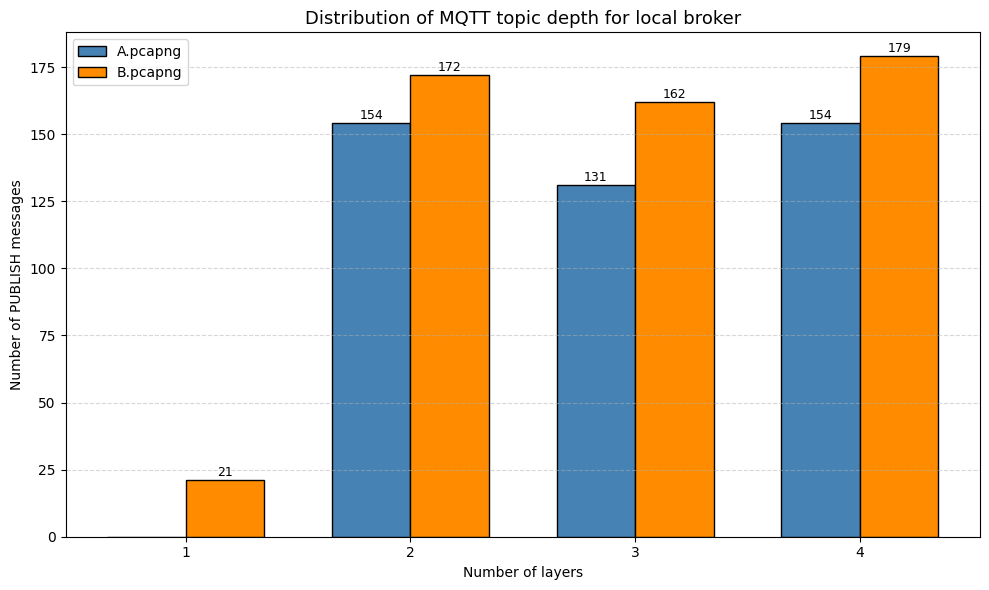

In [2]:
import nest_asyncio
nest_asyncio.apply()

# Python wrapper for tshark (Wireshark command-line tool)
import pyshark
import matplotlib.pyplot as plt
from collections import Counter

# Compute topic depth as the number of '/' separators + 1
def get_topic_depth(topic):
    return len(topic.split('/'))

# A.pcapng
# Filter: MQTT PUBLISH messages (msgtype=3) directed to the local broker
# (127.0.0.1) on TCP port 1883
cap_a = pyshark.FileCapture(
    '/content/sample_data/A.pcapng',
    display_filter='mqtt.msgtype == 3 && tcp.dstport == 1883 && ip.dst == 127.0.0.1'
)
depths_a = []
for pkt in cap_a:
    try:
        # Extract topic string and compute its depth
        depths_a.append(get_topic_depth(pkt.mqtt.topic))
    except AttributeError:
        # Skip packets where the MQTT topic field is not present
        continue
cap_a.close()
# Count occurrences of each depth level
counter_a = Counter(depths_a)

# B.pcapng
# Filter: MQTT PUBLISH messages directed to the local broker
# (IPv6 loopback ::1) on TCP port 1883
cap_b = pyshark.FileCapture(
    '/content/sample_data/B.pcapng',
    display_filter='mqtt.msgtype == 3 && tcp.dstport == 1883 && ipv6.dst == ::1'
)
depths_b = []
for pkt in cap_b:
    try:
        # Extract topic string and compute its depth
        depths_b.append(get_topic_depth(pkt.mqtt.topic))
    except AttributeError:
        # Skip packets where the MQTT topic field is not present
        continue
cap_b.close()
# Count occurrences of each depth level
counter_b = Counter(depths_b)

# Histogram
# Compute the union of all depth levels found in both captures
all_depths = sorted(set(list(counter_a.keys()) + list(counter_b.keys())))
# x positions for the grouped bars
x = list(range(len(all_depths)))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Plot bars for A.pcapng
bars_a = ax.bar([i - width/2 for i in x],
                [counter_a.get(d, 0) for d in all_depths],
                width, label='A.pcapng', color='steelblue', edgecolor='black')

# Plot bars for B.pcapng
bars_b = ax.bar([i + width/2 for i in x],
                [counter_b.get(d, 0) for d in all_depths],
                width, label='B.pcapng', color='darkorange', edgecolor='black')

# Axis labels, title and grid
ax.set_title('Distribution of MQTT topic depth for local broker', fontsize=13)
ax.set_xlabel('Number of layers')
ax.set_ylabel('Number of PUBLISH messages')
ax.set_xticks(x)
ax.set_xticklabels(all_depths)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate each bar with its exact count value
for bar in bars_a:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                str(int(h)), ha='center', va='bottom', fontsize=9)
for bar in bars_b:
    h = bar.get_height()
    if h > 0:
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
                str(int(h)), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
# Save the figure as a PNG file
plt.savefig('CQ8_histogram.png', dpi=150)
plt.show()